In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import shap
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
#from sklearn.linear_model import LogisticRegression
#from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import ElasticNetCV
from sklearn.linear_model import Ridge
#from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler

In [3]:
# Load the data

In [12]:
#Data = pd.read_csv('/Users/blessingodeleye/Documents/VR_data/Labelled_data_set.csv')
Data = pd.read_csv('/Users/blessingodeleye/Documents/VR_data2/Data.csv')
Data = Data.iloc[:, 1: -13]

In [13]:
Data

,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate
0,62.06,16.11,0.00,16.11,16.11,16.11,0.00
1,68.85,14.52,0.00,16.11,14.92,10.58,0.00
2,76.57,13.06,0.00,16.11,13.61,8.01,0.00
3,79.07,12.65,0.00,16.11,12.95,6.71,0.00
4,69.74,14.34,0.00,16.11,13.88,6.33,0.21
...,...,...,...,...,...,...,...
10327,36.55,27.36,27.36,115.83,67.79,26.53,1.09
10328,10.96,91.25,27.36,115.83,67.82,30.96,1.28
10329,11.73,85.22,27.36,115.83,67.83,30.43,0.84
10330,23.38,42.78,27.36,115.83,67.81,31.04,0.63


In [14]:
Data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10332 entries, 0 to 10331
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   FPS                      10332 non-null  float64
 1   Frame Duration (ms)      10332 non-null  float64
 2   Min Frame Duration (ms)  10332 non-null  float64
 3   Max Frame Duration (ms)  10332 non-null  float64
 4   Avg Frame Duration (ms)  10332 non-null  float64
 5   Std Dev (ms)             10332 non-null  float64
 6   Entropy Framerate        10332 non-null  float64
dtypes: float64(7)
memory usage: 565.2 KB


In [15]:
Data.head(10)

,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate
0,62.06,16.11,0.00,16.11,16.11,16.11,0.00
1,68.85,14.52,0.00,16.11,14.92,10.58,0.00
2,76.57,13.06,0.00,16.11,13.61,8.01,0.00
3,79.07,12.65,0.00,16.11,12.95,6.71,0.00
4,69.74,14.34,0.00,16.11,13.88,6.33,0.21
5,77.87,12.84,12.65,16.11,13.26,1.50,0.09
6,69.38,14.41,12.65,14.52,13.88,0.88,0.31
7,68.05,14.69,12.65,14.69,14.28,1.12,0.41
8,69.73,14.34,12.65,14.69,14.31,1.01,0.30
9,80.83,12.37,12.37,14.69,13.51,0.90,0.07


In [20]:
Data.shape

(10332, 7)

In [21]:
# Select input features and target variable

In [22]:
X = Data.iloc[:, 0 :]
X.drop(['FPS'], axis=1, inplace=True)

In [23]:
y = Data['FPS']

In [24]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [25]:
#Scale data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [26]:
# Fit a random forest regressor and get the feature importances

In [27]:
rf = RandomForestRegressor()
rf.fit(X_train, y_train)

RandomForestRegressor()

In [28]:
importances = rf.feature_importances_

In [29]:
indices = np.argsort(importances)[::-1]

In [30]:
# Get feature names
feature_names = X.columns

In [31]:
# Get feature names
feature_names = X.columns

In [32]:
# Print feature ranking
print("Feature ranking:")
for f in range(X.shape[1]):
    print("%d. feature %d (%f) - %s" % (f + 1, indices[f], importances[indices[f]], feature_names[indices[f]]))

Feature ranking:
1. feature 0 (0.999912) - Frame Duration (ms)
2. feature 1 (0.000074) - Min Frame Duration (ms)
3. feature 4 (0.000007) - Std Dev (ms)
4. feature 5 (0.000005) - Entropy Framerate
5. feature 3 (0.000002) - Avg Frame Duration (ms)
6. feature 2 (0.000001) - Max Frame Duration (ms)


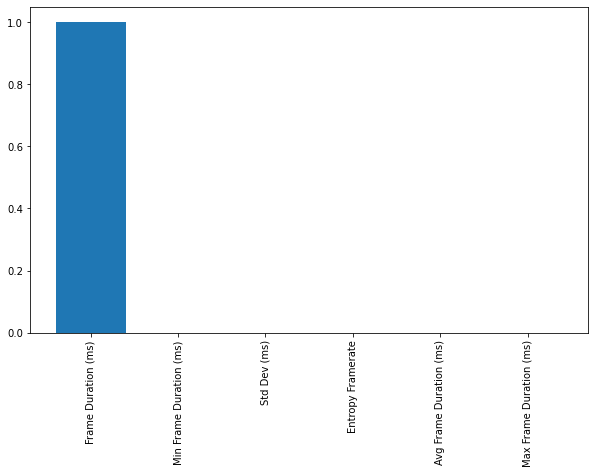

In [33]:
# Plot feature importances
plt.figure(figsize=(10, 6))
plt.bar(range(len(importances)), importances[indices])
plt.xticks(range(len(importances)), feature_names[indices], rotation=90)
plt.show()

In [34]:
# Calculate permutation importances

In [35]:
result_rf = permutation_importance(rf, X_test, y_test, n_repeats=50, random_state=42)

In [36]:
# Print feature ranking
sorted_idx = result_rf.importances_mean.argsort()[::-1]
for i in sorted_idx:
    print(f"{X.columns[i]:<15} {result_rf.importances_mean[i]:.3f} +/- {result_rf.importances_std[i]:.3f}")

Frame Duration (ms) 2.002 +/- 0.043
Min Frame Duration (ms) 0.000 +/- 0.000
Max Frame Duration (ms) -0.000 +/- 0.000
Avg Frame Duration (ms) -0.000 +/- 0.000
Entropy Framerate -0.000 +/- 0.000
Std Dev (ms)    -0.000 +/- 0.000


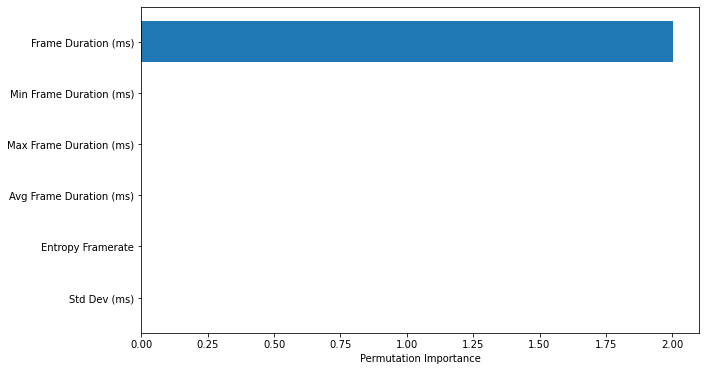

In [37]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result_rf.importances_mean.argsort()
plt.barh(range(X.shape[1]), result_rf.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [38]:
# Fit a linear regression model

In [39]:
lr = LinearRegression()
lr.fit(X_train, y_train)

LinearRegression()

In [40]:
# Get the coefficient values and feature names
coef_lr = lr.coef_

In [41]:
feature_names = X.columns

In [42]:
'Feature ranking'
for i in range(len(feature_names)):
    print("%s: %f" % (feature_names[i], abs(coef_lr[i])))

Frame Duration (ms): 3.501096
Min Frame Duration (ms): 1.213955
Max Frame Duration (ms): 0.863083
Avg Frame Duration (ms): 16.902435
Std Dev (ms): 5.590618
Entropy Framerate: 0.672335


In [43]:
# Print the feature importance in order of highest to lowest absolute coefficient values
print("Feature importance:")
sorted_indices = np.argsort(abs(coef_lr))[::-1]
for i in sorted_indices:
    print("%s: %f" % (feature_names[i], abs(coef_lr[i])))

Feature importance:
Avg Frame Duration (ms): 16.902435
Std Dev (ms): 5.590618
Frame Duration (ms): 3.501096
Min Frame Duration (ms): 1.213955
Max Frame Duration (ms): 0.863083
Entropy Framerate: 0.672335


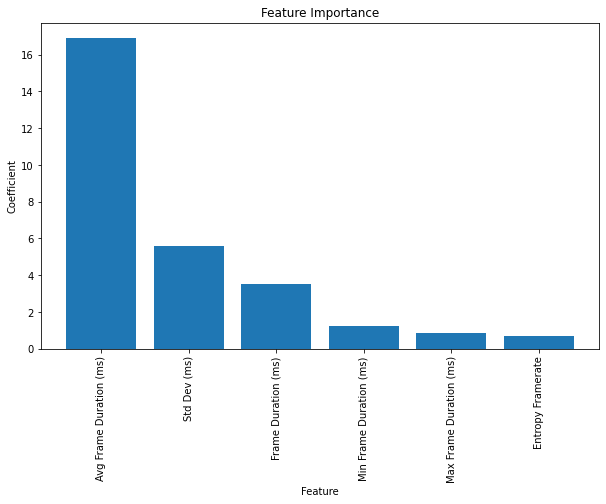

In [44]:
# Plot feature importance in order of highest to lowest absolute coefficient values
sorted_indices = np.argsort(abs(coef_lr))[::-1]
sorted_features = [feature_names[i] for i in sorted_indices]
sorted_coefficients = [abs(coef_lr[i]) for i in sorted_indices]

plt.figure(figsize=(10, 6))
plt.bar(sorted_features, sorted_coefficients)
plt.xticks(rotation=90)
plt.xlabel('Feature')
plt.ylabel('Coefficient')
plt.title('Feature Importance')
plt.show()

In [45]:
# Calculate permutation importances

In [46]:
result_lr = permutation_importance(lr, X_test, y_test, n_repeats=50, random_state=42)

In [47]:
# Print permutation importances
print("Permutation importances:")
for i in result_lr.importances_mean.argsort()[::-1]:
    print("%s: %f" % (feature_names[i], result_lr.importances_mean[i]))

Permutation importances:
Avg Frame Duration (ms): 1.334563
Std Dev (ms): 0.104146
Frame Duration (ms): 0.047696
Min Frame Duration (ms): 0.006376
Max Frame Duration (ms): 0.004540
Entropy Framerate: 0.002992


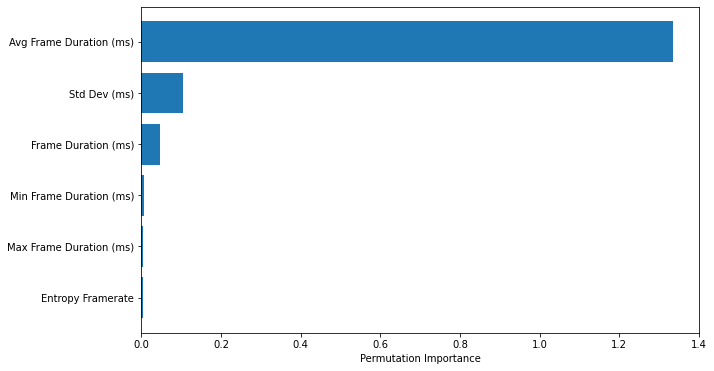

In [48]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result_lr.importances_mean.argsort()
plt.barh(range(X.shape[1]), result_lr.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [49]:
#Lasso regression

In [50]:
l_reg = Lasso(alpha=0.1)
l_reg.fit(X_train, y_train)

Lasso(alpha=0.1)

In [51]:
l_reg_abs = abs(l_reg.coef_)

In [52]:
# Create a DataFrame to store the feature importance scores and names
feature_importance = pd.DataFrame({'Feature_names': X.columns, 'Importance': l_reg_abs})

In [53]:
# Sort the features by importance and print the ranked list
feature_importance = feature_importance.sort_values('Importance', ascending=False)

In [54]:
feature_importance

,Feature_names,Importance
3,Avg Frame Duration (ms),17.123275
4,Std Dev (ms),4.298440
0,Frame Duration (ms),3.454499
1,Min Frame Duration (ms),0.623882
5,Entropy Framerate,0.482813
2,Max Frame Duration (ms),0.000000


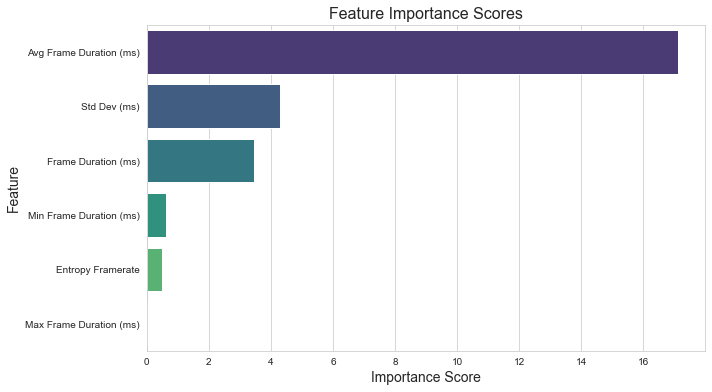

In [55]:
# Create a barplot of the feature importance scores>
plt.figure(figsize=(10, 6))
sns.set_style('whitegrid')
sns.barplot(x='Importance', y='Feature_names', data=feature_importance, palette='viridis')
plt.xlabel('Importance Score', fontsize=14)
plt.ylabel('Feature', fontsize=14)
plt.title('Feature Importance Scores', fontsize=16)
plt.show()

In [56]:
# Calculate permutation importances

In [57]:
result_l_reg= permutation_importance(l_reg, X_test, y_test, n_repeats=50, random_state=42)

In [58]:
# Print permutation importances
print("Permutation importances:")
for i in result_l_reg.importances_mean.argsort()[::-1]:
    print("%s: %f" % (feature_names[i], result_l_reg.importances_mean[i]))

Permutation importances:
Avg Frame Duration (ms): 1.375434
Std Dev (ms): 0.062620
Frame Duration (ms): 0.047552
Min Frame Duration (ms): 0.002204
Entropy Framerate: 0.001950
Max Frame Duration (ms): 0.000000


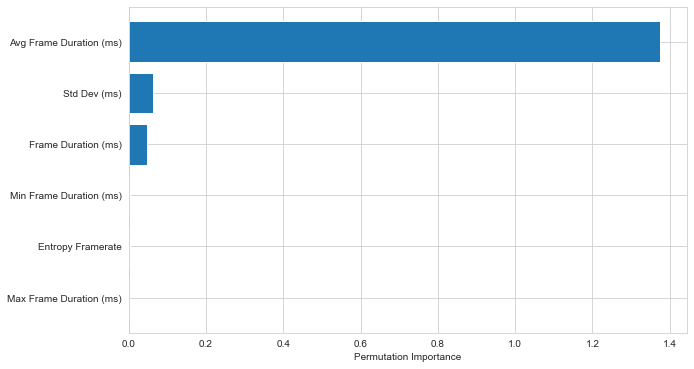

In [59]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result_l_reg.importances_mean.argsort()
plt.barh(range(X.shape[1]), result_l_reg.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [60]:
#Elastic Net Feature Importance

In [61]:
# Create Elastic Net object
enet = ElasticNetCV(cv=5, random_state=0)
enet.fit(X_train, y_train)

ElasticNetCV(cv=5, random_state=0)

In [62]:
# Extract feature importance from coefficients
feature_importance = abs(enet.coef_)

In [63]:
# Normalize the feature importance scores
feature_importance_normalized = feature_importance / feature_importance.sum()

In [64]:
# Create a dictionary of feature names and their importance scores
features_dict = dict(zip(X.columns, feature_importance_normalized))

In [65]:
# Sort the dictionary in descending order of importance scores
sorted_features = sorted(features_dict.items(), key=lambda x: x[1], reverse=True)

In [66]:
# Print the feature importance scores
for feature in sorted_features:
    print(feature[0], ": ", feature[1])

Avg Frame Duration (ms) :  0.6146935477735012
Std Dev (ms) :  0.16757250384263622
Frame Duration (ms) :  0.13360302125746015
Min Frame Duration (ms) :  0.05243577180675832
Entropy Framerate :  0.03169515531964414
Max Frame Duration (ms) :  0.0


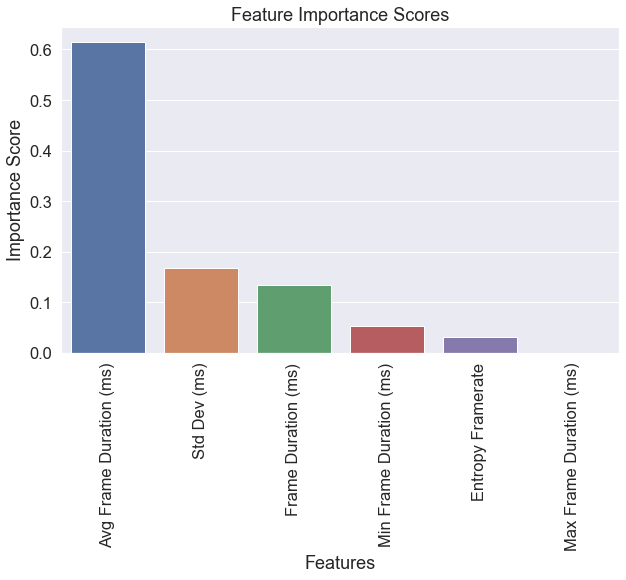

In [67]:
# Create a bar plot of feature importance scores
sns.set_style("whitegrid")
sns.set(font_scale=1.5)
fig, ax = plt.subplots(figsize=(10,6))
sns.barplot(x=[x[0] for x in sorted_features], y=[x[1] for x in sorted_features], ax=ax)
ax.set_title("Feature Importance Scores")
ax.set_xlabel("Features")
ax.set_ylabel("Importance Score")
plt.xticks(rotation=90)
plt.show()

In [68]:
# Calculate permutation importances

In [69]:
result_enet= permutation_importance(enet, X_test, y_test, n_repeats=50, random_state=42)

In [70]:
# Print permutation importances
print("Permutation importances:")
for i in result_enet.importances_mean.argsort()[::-1]:
    print("%s: %f" % (feature_names[i], result_enet.importances_mean[i]))

Permutation importances:
Avg Frame Duration (ms): 1.265049
Std Dev (ms): 0.064292
Frame Duration (ms): 0.050684
Min Frame Duration (ms): 0.009024
Entropy Framerate: 0.004540
Max Frame Duration (ms): 0.000000


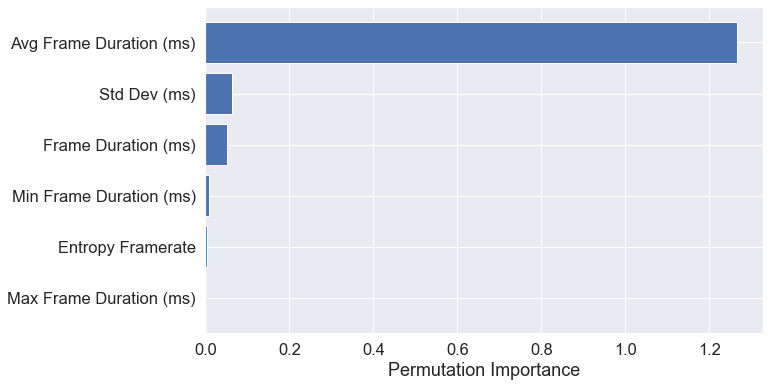

In [71]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result_enet.importances_mean.argsort()
plt.barh(range(X.shape[1]), result_enet.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [72]:
# Ridge model

In [73]:
ridge = Ridge()
ridge.fit(X_train, y_train)

Ridge()

In [74]:
# Extract feature importance from coefficients
feature_importance = abs(ridge.coef_)

In [75]:
# Normalize the feature importance scores
feature_importance_normalized = feature_importance / feature_importance.sum()

In [76]:
# Create a dictionary of feature names and their importance scores
features_dict = dict(zip(X.columns, feature_importance_normalized))

In [77]:
# Sort the dictionary in descending order of importance scores
sorted_features = sorted(features_dict.items(), key=lambda x: x[1], reverse=True)

In [78]:
sorted_features

[('Avg Frame Duration (ms)', 0.5882024253196849),
 ('Std Dev (ms)', 0.1943223411970338),
 ('Frame Duration (ms)', 0.12188880459777127),
 ('Min Frame Duration (ms)', 0.042317466269461375),
 ('Max Frame Duration (ms)', 0.029815522938123996),
 ('Entropy Framerate', 0.02345343967792454)]

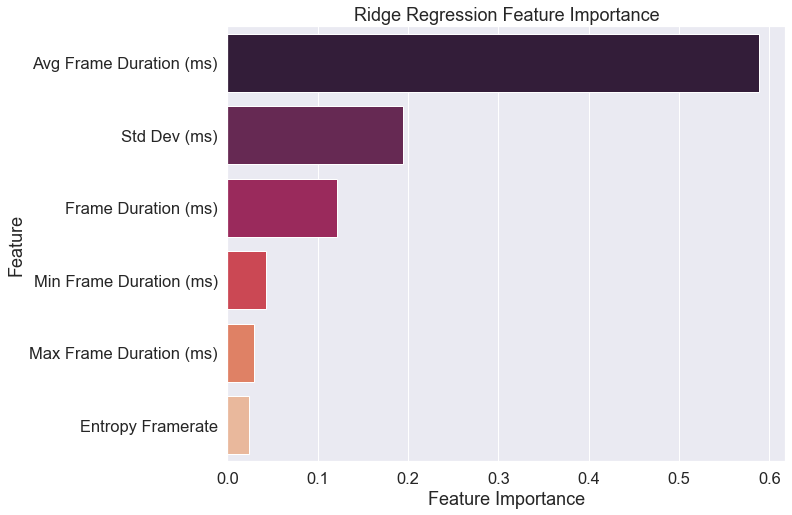

In [79]:
plt.figure(figsize = (10, 8))
sns.set_style("whitegrid")
sns.set(font_scale=1.5)
sns.barplot(x=[x[1] for x in sorted_features], y=[x[0] for x in sorted_features], palette="rocket")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Ridge Regression Feature Importance")
plt.show()

In [80]:
# Calculate permutation importances

In [81]:
result_ridge= permutation_importance(ridge, X_test, y_test, n_repeats=50, random_state=42)

In [82]:
# Print permutation importances
print("Permutation importances:")
for i in result_ridge.importances_mean.argsort()[::-1]:
    print("%s: %f" % (feature_names[i], result_ridge.importances_mean[i]))

Permutation importances:
Avg Frame Duration (ms): 1.334032
Std Dev (ms): 0.103829
Frame Duration (ms): 0.047721
Min Frame Duration (ms): 0.006398
Max Frame Duration (ms): 0.004488
Entropy Framerate: 0.003003


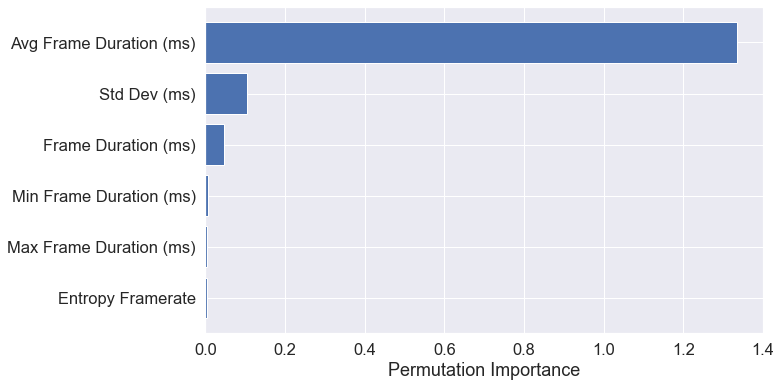

In [83]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result_ridge.importances_mean.argsort()
plt.barh(range(X.shape[1]), result_ridge.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()